In [1]:
import pandas as pd
import pickle
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import shap
import numpy as np
import pandas as pd
import os


In [2]:

datafile = "Dataset_14_features.xlsx"

df = pd.read_excel(datafile)

with open('14_feat_NGB_model.pkl', 'rb') as file:
    NGB_model = pickle.load(file)

X = df.drop(['Formulation_number', 'Modification','Drug', 'Cross_linker', 'DL'], axis='columns')
y = df['DL']

In [3]:
stdScale = StandardScaler().fit(X)
X_scale = stdScale.transform(X)

In [4]:
NGB_model

NGBRegressor(Base=DecisionTreeRegressor(max_depth=16), col_sample=0.8,
             learning_rate=0.1, minibatch_frac=0.8, n_estimators=100,
             random_state=RandomState(MT19937) at 0x1DF911A2A40)

In [5]:
bestModel = NGB_model
bestModel.fit(X, y)
explainer = shap.TreeExplainer(NGB_model)
shap_values = explainer(X)

[iter 0] loss=4.3042 val_loss=0.0000 scale=2.0000 norm=29.3670


c:\Users\Afra\AppData\Local\Programs\Python\Python39\lib\site-packages\shap\explainers\_tree.py:1403: UserWarning: Translating model_output="raw" to model_output=0 for the 0-th parameter in the distribution. Use model_output=0 directly to avoid this warning.
  warnings.warn(


In [7]:
shap_values

.values =
array([[  1.77367833,  -7.37072003,   0.38209899, ...,  -4.18927047,
         -0.97788463,  -2.10977809],
       [  1.71119879,  -7.25230734,   0.36532677, ...,  -2.62006953,
         -0.79058144,  -1.53938063],
       [ -0.12400701,  -6.36889273,   0.21958509, ...,   0.99886171,
         -1.87585877,  -2.2715062 ],
       ...,
       [ -2.51788103,  -1.0658753 ,   0.43621746, ...,   4.62710934,
         -0.41055196,   3.22964226],
       [  1.78392213,   0.28156062,   0.42853184, ...,   5.37396484,
         -0.75916825,  -0.07491753],
       [ -0.02248   , -11.42120381,   0.38924578, ...,   2.5038148 ,
         -0.65817073,  -2.91987652]])

.base_values =
array([24.61064002, 24.61064002, 24.61064002, 24.61064002, 24.61064002,
       24.61064002, 24.61064002, 24.61064002, 24.61064002, 24.61064002,
       24.61064002, 24.61064002, 24.61064002, 24.61064002, 24.61064002,
       24.61064002, 24.61064002, 24.61064002, 24.61064002, 24.61064002,
       24.61064002, 24.61064002, 24.6

In [8]:
shap_values.values

array([[  1.77367833,  -7.37072003,   0.38209899, ...,  -4.18927047,
         -0.97788463,  -2.10977809],
       [  1.71119879,  -7.25230734,   0.36532677, ...,  -2.62006953,
         -0.79058144,  -1.53938063],
       [ -0.12400701,  -6.36889273,   0.21958509, ...,   0.99886171,
         -1.87585877,  -2.2715062 ],
       ...,
       [ -2.51788103,  -1.0658753 ,   0.43621746, ...,   4.62710934,
         -0.41055196,   3.22964226],
       [  1.78392213,   0.28156062,   0.42853184, ...,   5.37396484,
         -0.75916825,  -0.07491753],
       [ -0.02248   , -11.42120381,   0.38924578, ...,   2.5038148 ,
         -0.65817073,  -2.91987652]])

Chitosan

In [6]:
MOD_chitosan = df.loc[df['Modification'] == 'Chitosan']
MOD_chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
0,1,Chitosan,Doxorubicin hydrochloride,TPP,0.07,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,489.30,12.40,6,0.42310
1,1,Chitosan,Doxorubicin hydrochloride,TPP,0.10,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,342.20,15.30,6,0.42310
2,1,Chitosan,Doxorubicin hydrochloride,TPP,0.17,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,209.60,14.90,6,0.42310
3,2,Chitosan,Vancomycin,Sodium carboxymethylcellulose,0.25,10.00,1,2,0.0,0.0,0.0,250000.00,4.50,1449.25,2.99,194.70,52.00,19,0.10620
4,2,Chitosan,Vancomycin,Sodium alginate,0.25,10.00,1,2,0.0,0.0,0.0,140000.00,3.60,1449.25,2.99,350.10,51.80,19,0.10620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,19,Chitosan,oxaliplatin,TPP,0.27,0.25,1,2,0.0,0.0,0.0,367.86,0.89,397.29,1.36,188.40,12.40,2,1.55510
86,20,Chitosan,Levofloxacin,TPP,0.40,1.00,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,161.90,4.23,1,1.54400
87,20,Chitosan,Levofloxacin,TPP,0.40,0.67,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,176.97,4.02,1,1.54400
88,20,Chitosan,Levofloxacin,TPP,0.40,0.50,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,283.97,3.13,1,1.54400


In [7]:
MOD_chitosan.loc[[23]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
23,6,Chitosan,B12,TPP,0.46,0.26,2,2,0.0,0.0,0.0,367.86,0.89,1355.4,1.82,326.0,5.16,9,3.40921


In [11]:
shap_values.values[23]

array([-1.32885578, -7.40963619, -3.08389491, -1.21682198,  0.08020906,
       -0.60298222, -0.55823727,  0.10975605,  0.12674389,  0.21150046,
       -0.07883795, -4.33362473, -0.7728782 , -0.59308022])

<Figure size 1800x400 with 0 Axes>

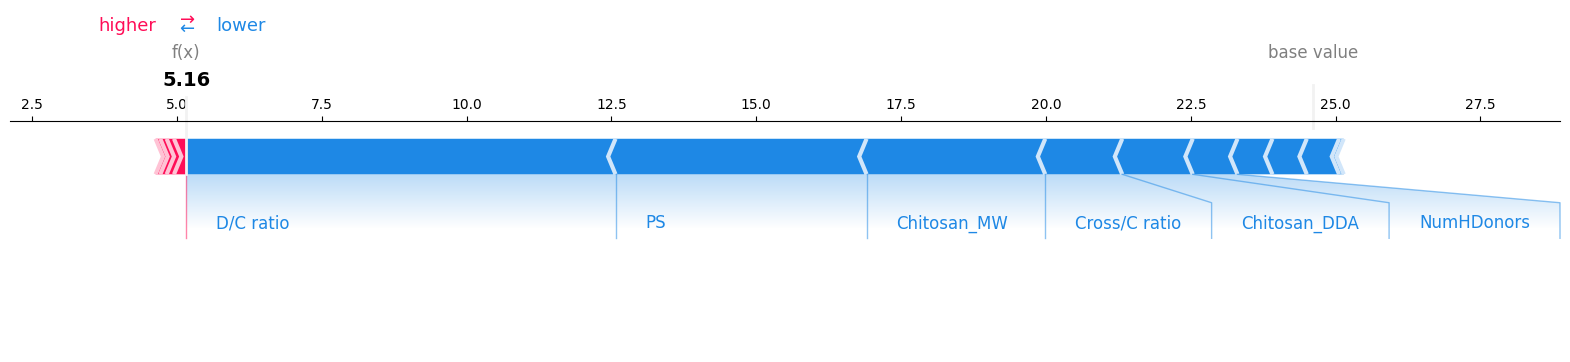

In [12]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[23],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/RF_ForcePlot_1.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_1.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_1.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_1.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_1.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)

Trimethyl Chitosan

In [13]:
MOD_Trimethyl_Chitosan = df.loc[df['Modification'] == 'Trimethyl Chitosan']
MOD_Trimethyl_Chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
90,22,Trimethyl Chitosan,Diclofenac Sodium,TPP,0.50,0.500,3,2,49.5,1.5,0.0,367.86,0.89,318.10,4.00,131.00,24.87,1,0.03340
91,22,Trimethyl Chitosan,Diclofenac Sodium,TPP,0.33,0.330,3,2,49.5,1.5,0.0,367.86,0.89,318.10,4.00,155.00,23.32,1,0.03340
92,22,Trimethyl Chitosan,Diclofenac Sodium,TPP,0.67,0.330,3,2,49.5,1.5,0.0,367.86,0.89,318.10,4.00,162.00,24.05,1,0.03340
93,22,Trimethyl Chitosan,Diclofenac Sodium,TPP,0.25,0.250,3,2,49.5,1.5,0.0,367.86,0.89,318.10,4.00,188.00,17.66,1,0.03340
94,23,Trimethyl Chitosan,Gemcitabine,TPP,0.33,0.500,3,3,49.5,1.5,0.0,367.86,0.89,299.66,11.52,382.97,22.12,3,-1.28860
95,23,Trimethyl Chitosan,B9,TPP,0.30,0.230,2,2,49.5,-0.3,0.0,367.86,0.89,441.40,3.38,606.00,14.64,6,-0.04480
96,23,Trimethyl Chitosan,C,TPP,0.35,0.240,2,2,49.5,-0.3,0.0,367.86,0.89,176.12,4.16,338.00,3.00,4,-1.40740
97,23,Trimethyl Chitosan,B12,TPP,0.22,0.210,2,2,49.5,-0.3,0.0,367.86,0.89,1355.40,1.82,335.00,7.76,9,3.40921
98,24,Trimethyl Chitosan,Progesterone,TPP,0.17,0.075,1,2,75.0,1.5,0.0,367.86,0.89,314.50,18.47,222.00,6.28,0,4.72350
99,24,Trimethyl Chitosan,Progesterone,TPP,0.17,0.370,1,2,75.0,1.5,0.0,367.86,0.89,314.50,18.47,227.00,24.00,0,4.72350


In [14]:
MOD_Trimethyl_Chitosan.loc[[90]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
90,22,Trimethyl Chitosan,Diclofenac Sodium,TPP,0.5,0.5,3,2,49.5,1.5,0.0,367.86,0.89,318.1,4.0,131.0,24.87,1,0.0334


In [15]:
shap_values.values[90]

array([-1.31960182, -1.33851039,  0.18722264, -0.32354339, -0.09152628,
        1.75757118, -0.62867632,  0.19339629,  0.43365595, -0.66694662,
        0.07930053,  3.35276242, -1.65356063,  0.27781646])

<Figure size 1800x400 with 0 Axes>

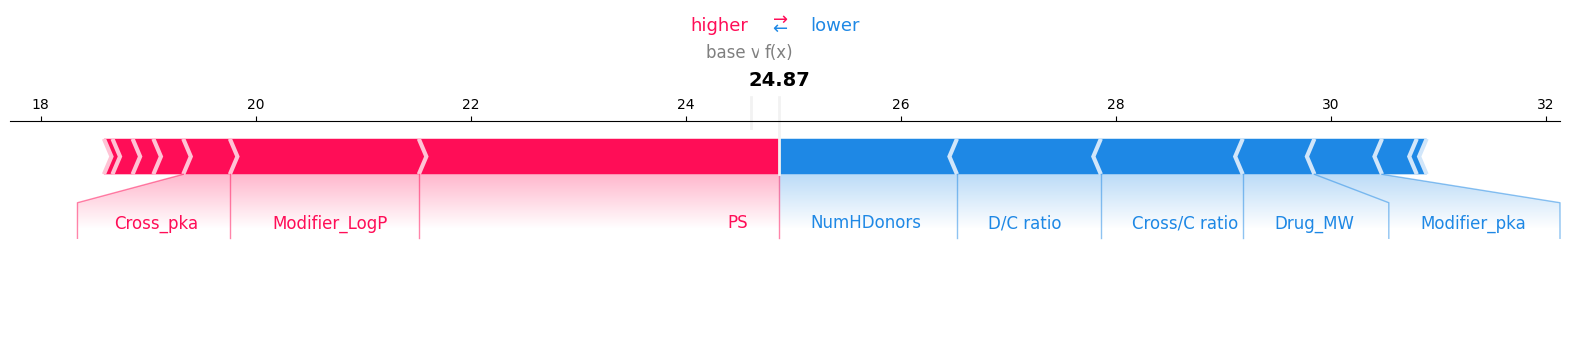

In [16]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[90],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/RF_ForcePlot_2.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_2.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_2.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_2.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_2.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)

Carboxymethyl chitosan

In [17]:
MOD_Carboxymethyl_chitosan = df.loc[df['Modification'] == 'Carboxymethyl chitosan']
MOD_Carboxymethyl_chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
102,25,Carboxymethyl chitosan,Carbamazepine,NaN,0.00,0.50,2,4,36.4,0.22,2.87,0.00,0.00,236.27,15.96,216.50,33.72,1,3.3872
103,25,Carboxymethyl chitosan,Carbamazepine,NaN,0.00,0.50,2,4,36.4,0.22,2.87,0.00,0.00,236.27,15.96,221.30,36.45,1,3.3872
104,25,Carboxymethyl chitosan,Carbamazepine,NaN,0.00,0.50,2,4,36.4,0.22,2.87,0.00,0.00,236.27,15.96,218.50,34.96,1,3.3872
105,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,82.0,0.22,2.87,110.98,3.09,580.00,8.01,207.00,0.96,6,0.4231
106,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,82.0,0.22,2.87,110.98,3.09,580.00,8.01,253.00,2.80,6,0.4231
107,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,82.0,0.22,2.87,110.98,3.09,580.00,8.01,270.00,3.40,6,0.4231
108,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,63.0,0.22,2.87,110.98,3.09,580.00,8.01,268.00,2.90,6,0.4231
109,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,74.0,0.22,2.87,110.98,3.09,580.00,8.01,252.00,3.40,6,0.4231
110,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,82.0,0.22,2.87,110.98,3.09,580.00,8.01,272.00,4.20,6,0.4231
111,26,Carboxymethyl chitosan,Doxorubicin hydrochloride,Calcium chloride,0.80,0.04,1,3,120.0,0.22,2.87,110.98,3.09,580.00,8.01,243.00,3.80,6,0.4231


In [18]:
MOD_Carboxymethyl_chitosan.loc[[126]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
126,28,Carboxymethyl chitosan,Curcumin,TPP,0.22,0.22,1,2,57.0,0.22,2.87,367.86,0.89,368.4,9.08,100.0,50.63,2,3.3699


In [19]:
shap_values.values[126]

array([ 2.97758649,  4.60969164,  0.9316128 ,  0.13791503,  0.07634378,
        1.98179617, -0.25146292,  0.55018158,  1.2405358 ,  1.21709435,
        0.40582602,  8.42357179, -0.00875647,  3.72742392])

<Figure size 1800x400 with 0 Axes>

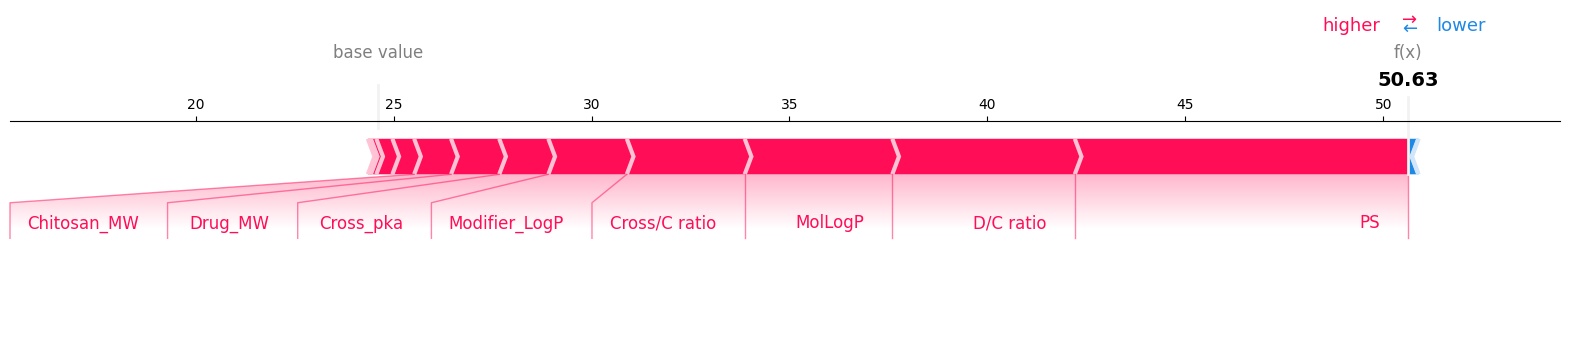

In [20]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[126],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/RF_ForcePlot_3.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_3.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_3.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_3.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_3.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)

Thiolated chitosan

In [21]:
MOD_Thiolated_chitosan = df.loc[df['Modification'] == 'Thiolated chitosan']
MOD_Thiolated_chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
128,30,Thiolated chitosan,Tobramycin,TPP,1.00,2.00,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,189.0,43.43,10,-6.2958
129,30,Thiolated chitosan,Tobramycin,TPP,0.50,1.49,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,156.0,48.76,10,-6.2958
130,30,Thiolated chitosan,Tobramycin,TPP,0.33,1.33,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,143.0,55.34,10,-6.2958
131,30,Thiolated chitosan,Tobramycin,TPP,0.25,1.25,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,139.0,45.56,10,-6.2958
132,30,Thiolated chitosan,Tobramycin,TPP,0.20,1.20,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,134.0,58.76,10,-6.2958
133,30,Thiolated chitosan,Tobramycin,TPP,0.17,1.16,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,112.0,63.19,10,-6.2958
134,30,Thiolated chitosan,Tobramycin,TPP,0.14,1.14,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,106.0,61.67,10,-6.2958
135,30,Thiolated chitosan,Tobramycin,TPP,0.13,1.12,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,73.0,87.45,10,-6.2958
136,30,Thiolated chitosan,Tobramycin,TPP,0.11,1.11,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,137.0,82.45,10,-6.2958
137,31,Thiolated chitosan,5-Fluorouracil,TPP,0.44,0.22,1,2,60.0,0.09,4.20,367.86,0.89,130.08,7.18,150.0,16.55,2,-0.7977


In [22]:
MOD_Thiolated_chitosan.loc[[131]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
131,30,Thiolated chitosan,Tobramycin,TPP,0.25,1.25,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,139.0,45.56,10,-6.2958


In [23]:
shap_values.values[131]

array([-4.21519652,  9.42291316,  0.23605282,  0.32113445,  0.12505876,
        0.37747606,  7.87846541, -0.05664933,  0.03915981,  3.17357653,
       -0.89770597,  1.00340487,  1.0520821 ,  2.48958786])

<Figure size 1800x400 with 0 Axes>

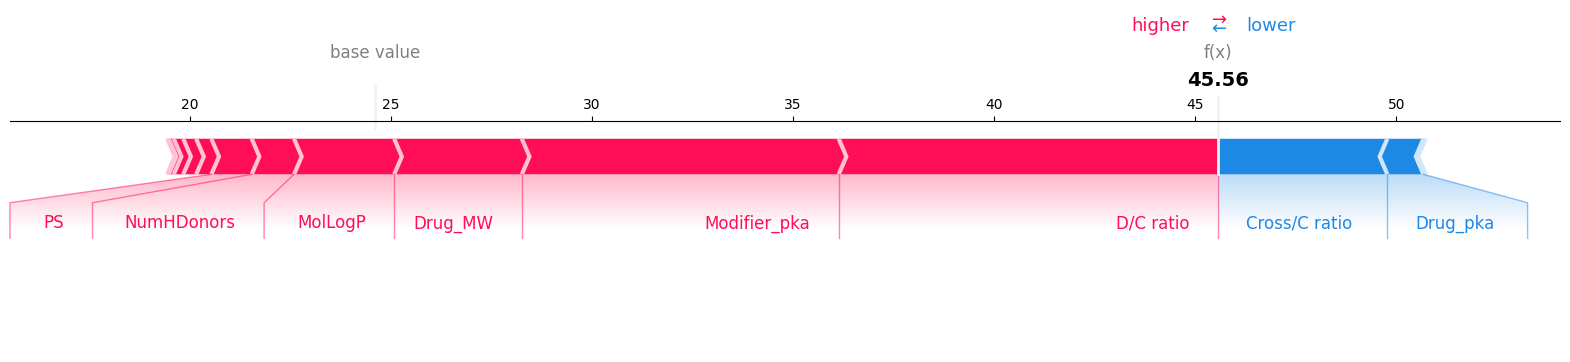

In [24]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[131],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/RF_ForcePlot_4.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_4.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_4.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_4.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/RF_ForcePlot_4.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)